# PROJECT TITLE: Michigan County Air Quality Explorer (2025)

# PROJECT OBJECTIVE
**To analyze air quality across Michigan counties in 2025 using the EPA Air Quality Index (AQI) dataset.**

# INTENDED AUDIANCE 
**Michigan residents, students, and anyone interested in understanding local air quality conditions.**

# MAIN QUESTION
**How does air quality vary across Michigan counties throughout the year?**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# DATASET DESCRIPTION

**Data Source:** U.S. EPA AirData, Daily AQI by County, 2025 (https://aqs.epa.gov/aqsweb/airdata/download_files.html)

**Observation Unit:** Each row represents one reported county-day AQI observation.

**Important Variables:**

- County Name: Michigan county where AQI was reported.

- Date: Date of the observation.

- AQI: Reported daily Air Quality Index.

- Category: EPA air quality classification.

- Defining Parameter: Pollutant determining the reported AQI.


In [2]:
# Load the original EPA daily AQI dataset for 2025
df = pd.read_csv("daily_aqi_by_county_2025.csv")

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Display the first five rows of the dataset
df.head(10)

Dataset shape: (323653, 10)


,State Name,county Name,State Code,County Code,Date,AQI,Category,Defining Parameter,Defining Site,Number of Sites Reporting
0,Alabama,Baldwin,1,3,2025-01-01,20,Good,PM2.5,01-003-0010,1
1,Alabama,Baldwin,1,3,2025-01-02,37,Good,PM2.5,01-003-0010,1
2,Alabama,Baldwin,1,3,2025-01-03,52,Moderate,PM2.5,01-003-0010,1
3,Alabama,Baldwin,1,3,2025-01-04,31,Good,PM2.5,01-003-0010,1
4,Alabama,Baldwin,1,3,2025-01-05,31,Good,PM2.5,01-003-0010,1
5,Alabama,Baldwin,1,3,2025-01-06,14,Good,PM2.5,01-003-0010,1
6,Alabama,Baldwin,1,3,2025-01-07,14,Good,PM2.5,01-003-0010,1
7,Alabama,Baldwin,1,3,2025-01-08,30,Good,PM2.5,01-003-0010,1
8,Alabama,Baldwin,1,3,2025-01-09,40,Good,PM2.5,01-003-0010,1
9,Alabama,Baldwin,1,3,2025-01-10,34,Good,PM2.5,01-003-0010,1


In [3]:
# Display the column names
print("Column names:")
print(df.columns.tolist())

# Check the data types and non-null values
print("\nDataset information:")
df.info()

# Check missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# Check the number of duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

Column names:
['State Name', 'county Name', 'State Code', 'County Code', 'Date', 'AQI', 'Category', 'Defining Parameter', 'Defining Site', 'Number of Sites Reporting']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 323653 entries, 0 to 323652
Data columns (total 10 columns):
 #   Column                     Non-Null Count   Dtype 
---  ------                     --------------   ----- 
 0   State Name                 323653 non-null  object
 1   county Name                323653 non-null  object
 2   State Code                 323653 non-null  int64 
 3   County Code                323653 non-null  int64 
 4   Date                       323653 non-null  object
 5   AQI                        323653 non-null  int64 
 6   Category                   323653 non-null  object
 7   Defining Parameter         323653 non-null  object
 8   Defining Site              323653 non-null  object
 9   Number of Sites Reporting  323653 non-null  int64 
dtypes: int64(4), object(6)

In [4]:
# Filter the dataset to include only Michigan
mi_df = df[df["State Name"] == "Michigan"].copy()

# Convert the Date column to datetime format
mi_df["Date"] = pd.to_datetime(mi_df["Date"])

# Check the number of rows and columns
print("Michigan dataset shape:", mi_df.shape)

# Count the number of reporting counties
print("Number of reporting counties:", mi_df["county Name"].nunique())

# Display the first five rows
mi_df.head()

Michigan dataset shape: (8373, 10)
Number of reporting counties: 27


,State Name,county Name,State Code,County Code,Date,AQI,Category,Defining Parameter,Defining Site,Number of Sites Reporting
132409,Michigan,Allegan,26,5,2025-01-01,21,Good,PM2.5,26-005-0003,1
132410,Michigan,Allegan,26,5,2025-01-02,25,Good,PM2.5,26-005-0003,1
132411,Michigan,Allegan,26,5,2025-01-03,21,Good,PM2.5,26-005-0003,1
132412,Michigan,Allegan,26,5,2025-01-04,18,Good,PM2.5,26-005-0003,1
132413,Michigan,Allegan,26,5,2025-01-05,26,Good,PM2.5,26-005-0003,1


In [5]:
# Check missing values in the Michigan dataset
print("Missing values:")
print(mi_df.isnull().sum())

# Check duplicate county-date records
duplicates = mi_df.duplicated(subset=["county Name", "Date"]).sum()
print("\nDuplicate county-date records:", duplicates)

# Check the minimum and maximum dates
print("\nStart date:", mi_df["Date"].min())
print("End date:", mi_df["Date"].max())

# Calculate the number of reporting days for each county
county_coverage = mi_df.groupby("county Name")["Date"].nunique()

# Display summary statistics for county reporting coverage
print("\nCounty reporting coverage:")
print(county_coverage.describe())

Missing values:
State Name                   0
county Name                  0
State Code                   0
County Code                  0
Date                         0
AQI                          0
Category                     0
Defining Parameter           0
Defining Site                0
Number of Sites Reporting    0
dtype: int64

Duplicate county-date records: 0

Start date: 2025-01-01 00:00:00
End date: 2025-12-31 00:00:00

County reporting coverage:
count     27.000000
mean     310.111111
std       81.320985
min       41.000000
25%      252.500000
50%      358.000000
75%      365.000000
max      365.000000
Name: Date, dtype: float64


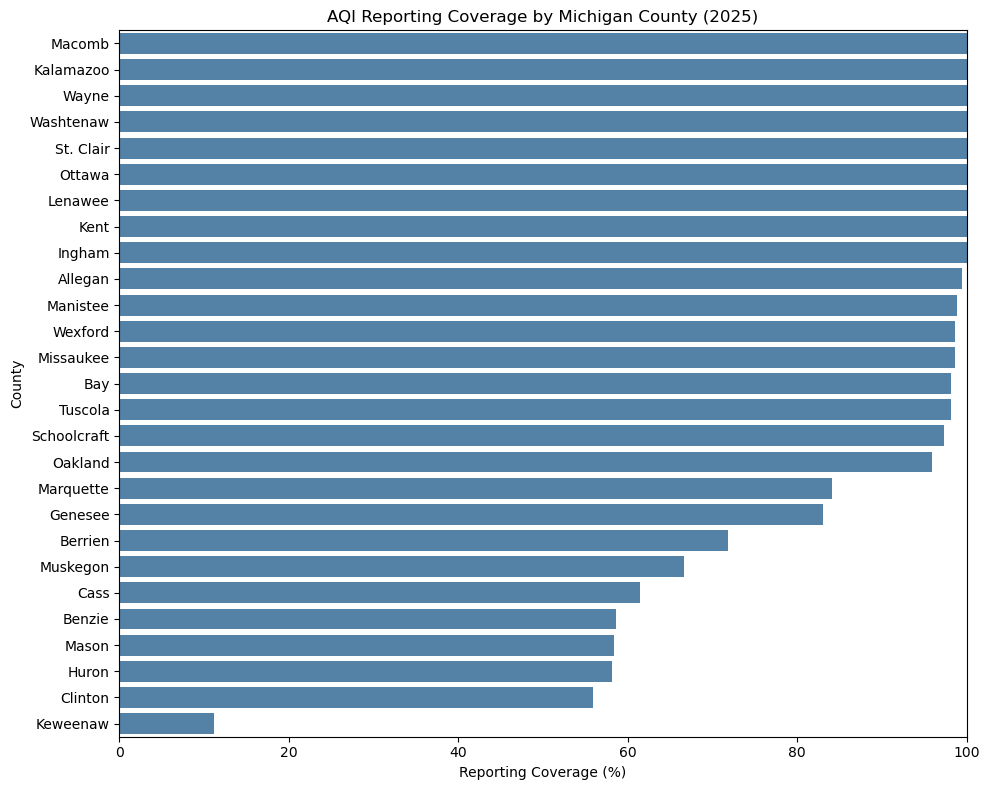

,County,Reported Days,Coverage (%)
0,Macomb,365,100.0
1,Kalamazoo,365,100.0
2,Wayne,365,100.0
3,Washtenaw,365,100.0
4,St. Clair,365,100.0
5,Ottawa,365,100.0
6,Lenawee,365,100.0
7,Kent,365,100.0
8,Ingham,365,100.0
9,Allegan,363,99.5


In [6]:
# Calculate the number of reported days for each county
coverage_df = mi_df.groupby("county Name")["Date"].nunique().reset_index()

# Rename the columns
coverage_df.columns = ["County", "Reported Days"]

# Calculate the reporting coverage percentage for 2025
coverage_df["Coverage (%)"] = (
    coverage_df["Reported Days"] / 365 * 100
).round(1)

# Sort counties by reporting days
coverage_df = coverage_df.sort_values("Reported Days", ascending=False)

# Set the figure size
plt.figure(figsize=(10, 8))

# Create a horizontal bar chart of county reporting coverage
sns.barplot(
    data=coverage_df,
    x="Coverage (%)",
    y="County",
    color="steelblue"
)

# Add chart title and axis labels
plt.title("AQI Reporting Coverage by Michigan County (2025)")
plt.xlabel("Reporting Coverage (%)")
plt.ylabel("County")

# Set the percentage axis from 0 to 100
plt.xlim(0, 100)

# Improve the chart layout
plt.tight_layout()

# Display the chart
plt.show()


# Display the table below the chart
display(coverage_df.reset_index(drop=True))

# DATA QUALITY ASSESSMENT

The Michigan dataset contains 8,373 county-day observations from 27 counties in 2025. No missing values or duplicate county-date records were identified.

However, reporting coverage varies across counties. Some counties have observations for all 365 days, while Keweenaw County has only 41 reported days (11.2% coverage).

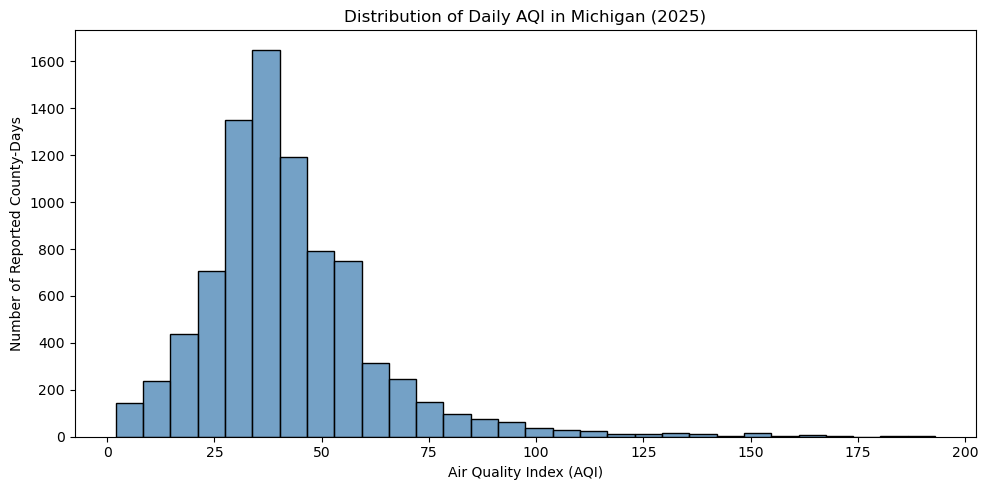

AQI Descriptive Statistics:
count    8373.00
mean       42.14
std        20.15
min         2.00
25%        31.00
50%        39.00
75%        51.00
90%        64.00
95%        77.00
max       193.00
Name: AQI, dtype: float64


In [7]:
# Set the figure size
plt.figure(figsize=(10, 5))

# Create a histogram of daily AQI values
sns.histplot(
    data=mi_df,
    x="AQI",
    bins=30,
    color="steelblue"
)

# Add chart title and axis labels
plt.title("Distribution of Daily AQI in Michigan (2025)")
plt.xlabel("Air Quality Index (AQI)")
plt.ylabel("Number of Reported County-Days")

# Improve the chart layout
plt.tight_layout()

# Display the histogram
plt.show()

# Calculate AQI descriptive statistics for Michigan only
print("AQI Descriptive Statistics:")
print(mi_df["AQI"].describe(
    percentiles=[.25, .5, .75, .9, .95]
).round(2))

**Interpretation:** 

Most reported AQI values are concentrated between approximately 20 and 60. The mean AQI is 42.14, and the median is 39. Higher AQI values occur less frequently, with a maximum recorded value of 193. The distribution is right-skewed, indicating that relatively high AQI observations are uncommon.

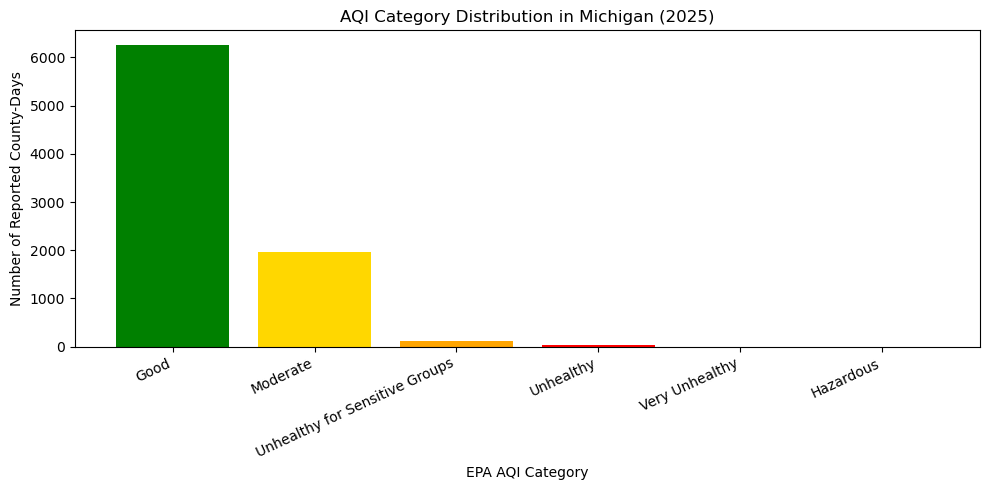

,AQI Category,AQI Range,Reported County-Days
0,Good,0–50,6251
1,Moderate,51–100,1972
2,Unhealthy for Sensitive Groups,101–150,123
3,Unhealthy,151–200,27
4,Very Unhealthy,201–300,0
5,Hazardous,301–500,0


In [20]:
# Define the EPA AQI categories in order
category_order = [
    "Good",
    "Moderate",
    "Unhealthy for Sensitive Groups",
    "Unhealthy",
    "Very Unhealthy",
    "Hazardous"
]

# Define EPA AQI ranges (category are taken from https://www.airnow.gov/?
category_ranges = [
    "0–50",
    "51–100",
    "101–150",
    "151–200",
    "201–300",
    "301–500"
]

# Count observations in each category, including categories with zero records
category_counts = mi_df["Category"].value_counts().reindex(
    category_order, fill_value=0
)

# Set the figure size
plt.figure(figsize=(10, 5))

# Create a bar chart of AQI category counts
plt.bar(
    category_counts.index,
    category_counts.values,
    color=["green", "gold", "orange", "red", "purple", "maroon"]
)

# Add chart title and axis labels
plt.title("AQI Category Distribution in Michigan (2025)")
plt.xlabel("EPA AQI Category")
plt.ylabel("Number of Reported County-Days")

# Rotate category labels for readability
plt.xticks(rotation=25, ha="right")

# Improve the chart layout
plt.tight_layout()

# Display the chart
plt.show()

# Create a summary table with AQI ranges
category_table = pd.DataFrame({
    "AQI Category": category_order,
    "AQI Range": category_ranges,
    "Reported County-Days": category_counts.values
})

# Display the table below the chart
display(category_table)

# Interpretation

Based on the categorization by EPA; most reported county-days fall within the Good AQI category (6,251 observations), followed by Moderate (1,972 observations). Only 150 observations fall into the Unhealthy for Sensitive Groups or Unhealthy categories. No observations for Very Unhealthy or Hazardous categories. 

In [9]:
# Calculate mean AQI and reporting days for each county
county_aqi = mi_df.groupby("county Name").agg(
    Mean_AQI=("AQI", "mean"),
    Reported_Days=("Date", "nunique")
).reset_index()

# Rename the county column
county_aqi = county_aqi.rename(columns={"county Name": "County"})

# Calculate reporting coverage percentage
county_aqi["Coverage (%)"] = (
    county_aqi["Reported_Days"] / 365 * 100
).round(1)

# Round the mean AQI values
county_aqi["Mean_AQI"] = county_aqi["Mean_AQI"].round(2)

# Sort counties by average AQI from highest to lowest
county_aqi = county_aqi.sort_values("Mean_AQI", ascending=False)

# Display the county-level AQI summary
county_aqi

,County,Mean_AQI,Reported_Days,Coverage (%)
25,Wayne,56.12,365,100.0
10,Kent,53.68,365,100.0
0,Allegan,49.09,363,99.5
9,Kalamazoo,45.82,365,100.0
24,Washtenaw,45.82,365,100.0
3,Berrien,45.07,262,71.8
19,Oakland,44.79,350,95.9
13,Macomb,44.36,365,100.0
22,St. Clair,44.02,365,100.0
12,Lenawee,43.27,365,100.0


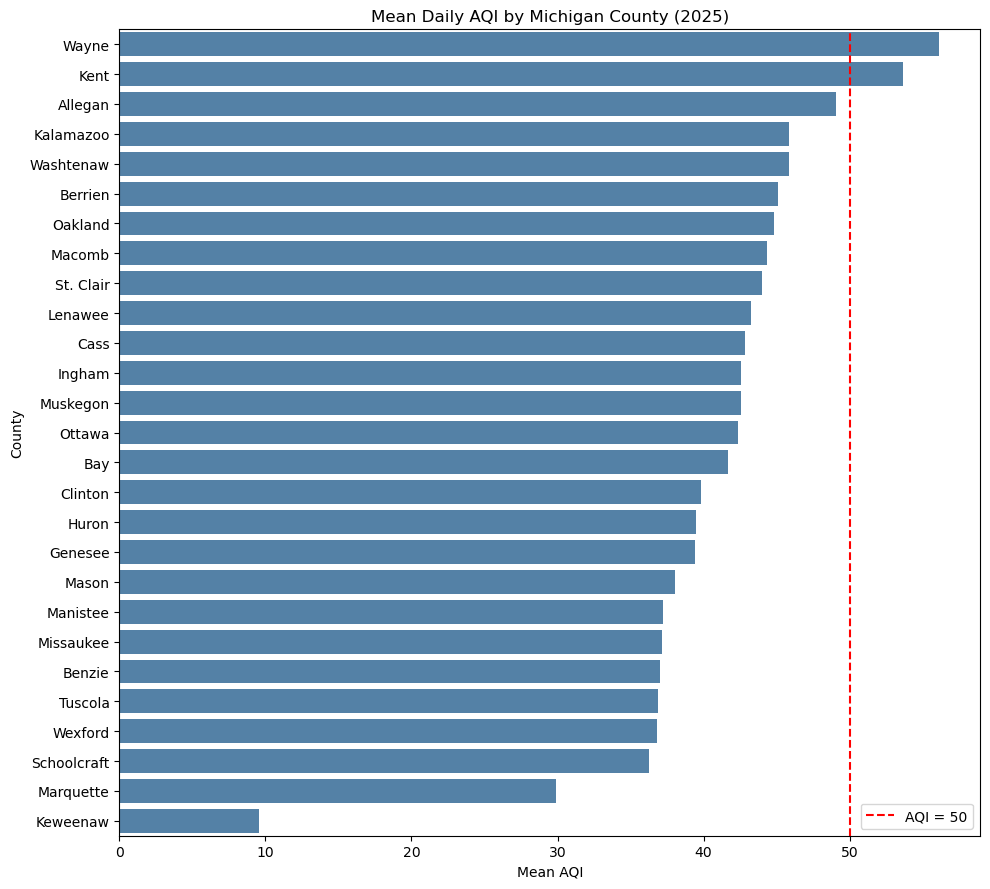

In [10]:
# Set the figure size
plt.figure(figsize=(10, 9))

# Create a horizontal bar chart of mean AQI by county
sns.barplot(
    data=county_aqi,
    x="Mean_AQI",
    y="County",
    color="steelblue"
)

# Add a reference line at AQI 50
plt.axvline(x=50, color="red", linestyle="--", label="AQI = 50")

# Add chart title and axis labels
plt.title("Mean Daily AQI by Michigan County (2025)")
plt.xlabel("Mean AQI")
plt.ylabel("County")

# Display the reference line legend
plt.legend()

# Improve the chart layout
plt.tight_layout()

# Display the chart
plt.show()

# Interpretation:

Wayne County has the highest mean AQI (56.12), followed by Kent County (53.68). Keweenaw County has the lowest reported mean AQI (9.59), but its reporting coverage is only 11.2%.

In [11]:
# Extract the month from the Date column
mi_df["Month"] = mi_df["Date"].dt.month

# Calculate the mean AQI and number of observations for each month
monthly_aqi = mi_df.groupby("Month").agg(
    Mean_AQI=("AQI", "mean"),
    Reported_Observations=("AQI", "count")
).reset_index()

# Round the monthly mean AQI values
monthly_aqi["Mean_AQI"] = monthly_aqi["Mean_AQI"].round(2)

# Display the monthly AQI summary
monthly_aqi

,Month,Mean_AQI,Reported_Observations
0,1,33.97,567
1,2,39.05,532
2,3,36.74,677
3,4,42.68,773
4,5,38.50,804
5,6,57.16,769
6,7,54.73,801
7,8,47.81,804
8,9,43.70,778
9,10,33.73,802


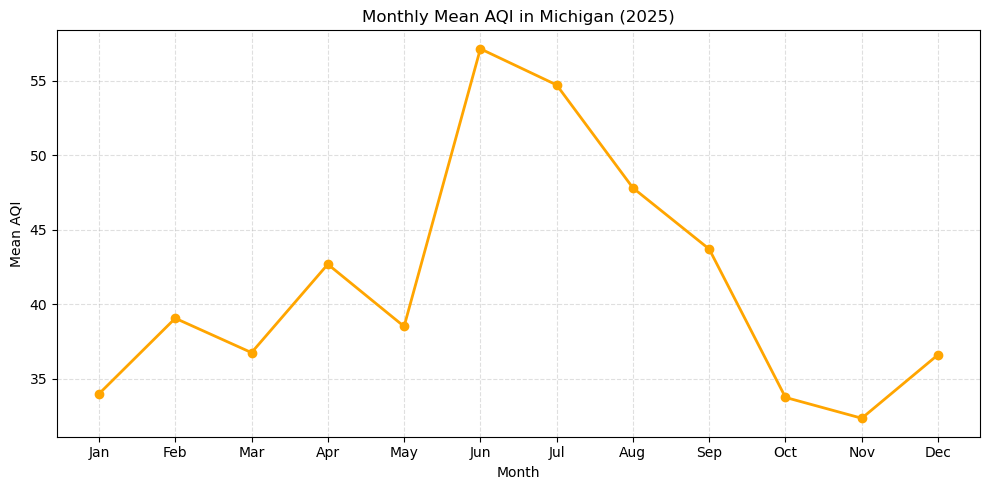

In [12]:
# Define month names for the x-axis
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# Set the figure size
plt.figure(figsize=(10, 5))

# Plot monthly mean AQI values
plt.plot(
    monthly_aqi["Month"],
    monthly_aqi["Mean_AQI"],
    marker="o",
    color="orange",
    linewidth=2
)

# Add chart title and axis labels
plt.title("Monthly Mean AQI in Michigan (2025)")
plt.xlabel("Month")
plt.ylabel("Mean AQI")

# Display month names on the x-axis
plt.xticks(range(1, 13), month_names)

# Add a grid for readability
plt.grid(True, linestyle="--", alpha=0.4)

# Improve the chart layout
plt.tight_layout()

# Display the chart
plt.show()

# Interpretation:

Monthly mean AQI varies throughout 2025. June has the highest mean AQI (57.16), followed by July (54.73), while November has the lowest (32.33). The results suggest that reported air quality was generally worse during the summer months. 

In [13]:
# Count the number of observations for each defining pollutant
pollutant_counts = mi_df["Defining Parameter"].value_counts()

# Calculate the percentage of observations for each pollutant
pollutant_percent = (
    mi_df["Defining Parameter"].value_counts(normalize=True) * 100
).round(2)

# Combine the counts and percentages into one table
pollutant_summary = pd.DataFrame({
    "Reported County-Days": pollutant_counts,
    "Percentage (%)": pollutant_percent
})

# Display the pollutant summary
pollutant_summary

,Reported County-Days,Percentage (%)
Defining Parameter,,
Ozone,4697,56.10
PM2.5,3656,43.66
NO2,11,0.13
PM10,9,0.11


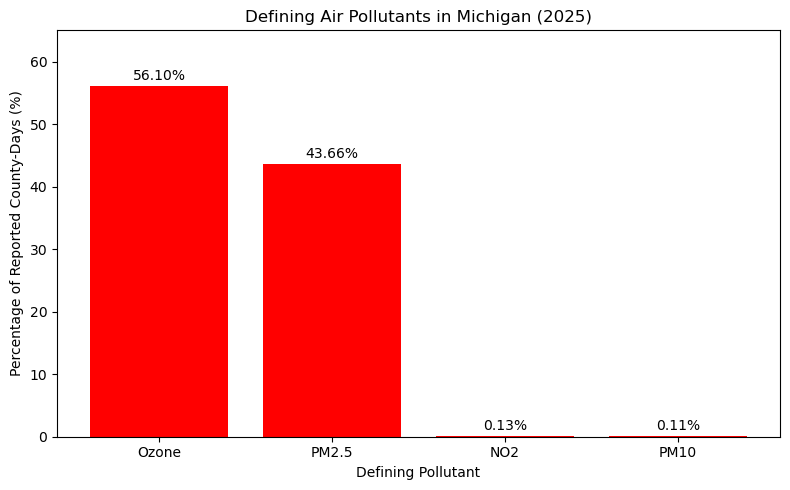

In [14]:
# Set the figure size
plt.figure(figsize=(8, 5))

# Create a bar chart showing the percentage for each pollutant
plt.bar(
    pollutant_summary.index,
    pollutant_summary["Percentage (%)"],
    color="red"
)

# Add chart title and axis labels
plt.title("Defining Air Pollutants in Michigan (2025)")
plt.xlabel("Defining Pollutant")
plt.ylabel("Percentage of Reported County-Days (%)")

# Set the y-axis range
plt.ylim(0, 65)

# Add percentage labels above the bars
for i, value in enumerate(pollutant_summary["Percentage (%)"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

# Improve the chart layout
plt.tight_layout()

# Display the chart
plt.show()

# Interpretation:

Ozone is the most frequently reported defining pollutant, accounting for 56.10% of county-day observations, followed by PM2.5 at 43.66%. NO2 and PM10 account for only a small proportion of observations. These percentages indicate how often each pollutant determined the daily AQI, not their relative concentrations.

In [15]:
# Install libraries for geographic data analysis and mapping
%pip install geopandas plotly

Note: you may need to restart the kernel to use updated packages.


In [16]:
# Import GeoPandas for geographic data analysis
import geopandas as gpd

# Load US county boundaries from the US Census Bureau
url = "https://www2.census.gov/geo/tiger/GENZ2024/shp/cb_2024_us_county_500k.zip"
counties = gpd.read_file(url)

# Filter the dataset to Michigan (State FIPS code: 26)
michigan_map = counties[counties["STATEFP"] == "26"].copy()

# Display the number of Michigan counties
print("Number of Michigan counties:", len(michigan_map))

# Display the first five rows
display(michigan_map[["NAME", "GEOID"]].head())

Number of Michigan counties: 83


,NAME,GEOID
66,Marquette,26103
67,Gogebic,26053
68,Monroe,26115
69,Presque Isle,26141
197,Oscoda,26135


In [17]:
# Calculate the mean AQI for each Michigan county
county_mean_aqi = mi_df.groupby("county Name")["AQI"].mean().reset_index()

# Rename columns to match the geographic dataset
county_mean_aqi.columns = ["NAME", "Mean_AQI"]

# Merge county AQI data with Michigan county boundaries
michigan_aqi_map = michigan_map.merge(
    county_mean_aqi,
    on="NAME",
    how="left"
)

# Count counties with and without AQI data
print("Counties with AQI data:", michigan_aqi_map["Mean_AQI"].notna().sum())
print("Counties without AQI data:", michigan_aqi_map["Mean_AQI"].isna().sum())

# Display the first five counties with AQI observations
display(
    michigan_aqi_map[
        michigan_aqi_map["Mean_AQI"].notna()
    ][["NAME", "Mean_AQI"]].head().round(2)
)

Counties with AQI data: 27
Counties without AQI data: 56


,NAME,Mean_AQI
0,Marquette,29.92
7,Wayne,56.12
10,Macomb,44.36
11,St. Clair,44.02
20,Huron,39.45


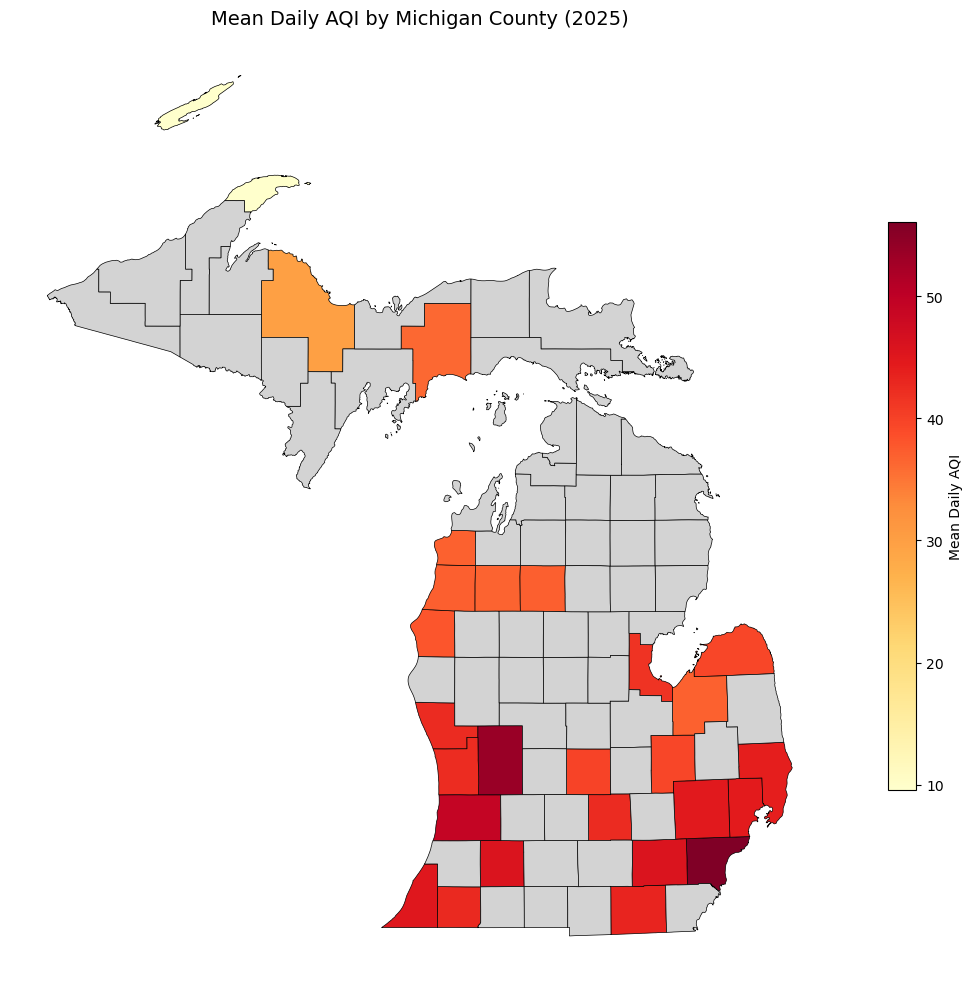

In [18]:
# Set the figure size
fig, ax = plt.subplots(figsize=(12, 10))

# Create a Michigan county map using mean AQI values
michigan_aqi_map.plot(
    column="Mean_AQI",
    cmap="YlOrRd",
    linewidth=0.5,
    edgecolor="black",
    legend=True,
    missing_kwds={
        "color": "lightgray",
        "edgecolor": "black",
        "label": "No AQI Data"
    },
    legend_kwds={
        "label": "Mean Daily AQI",
        "shrink": 0.6
    },
    ax=ax
)

# Add the map title
ax.set_title("Mean Daily AQI by Michigan County (2025)", fontsize=14)

# Remove the coordinate axes
ax.set_axis_off()

# Improve the map layout
plt.tight_layout()

# Display the map
plt.show()

# Interpretation

The map shows geographic differences in mean AQI across Michigan counties (mean daily AQI). Wayne and Kent counties have relatively high mean AQI values among the counties with observations. Of Michigan's 83 counties, 27 have AQI data and 56 have no observations in the dataset. Counties without data are displayed in gray and out of the scope of the project.

# LIMITATION

- AQI observations are available for only 27 of Michigan's 83 counties.

- Reporting coverage varies among counties, which may affect comparisons of annual mean AQI.

- The analysis uses data from 2025 only and does not establish long-term trends.

- A complete dataset with all the counties and all the days of the year would improve the accuracy and completeness of the analysis and allow more reliable comparisons across counties.

# CONCLUSION

The analysis shows that air quality varies across Michigan counties and throughout the year. Wayne and Kent counties have the highest mean AQI values among reporting counties. June and July show relatively higher monthly AQI. 

The results provide an overview of Michigan's reported air quality conditions in 2025, although incomplete county coverage limits statewide comparisons.